In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [167]:
def cenovna(x, dt, L, kapa, alpha, v0):
    ''''x - hitrost'''
    n = len(x)
    F = 0.5 * ((x[0]- v0)/dt)**2 + 0.5 * ((x[-1]-x[-2])/dt)**2
    exp = 0.5 * x[0] + 0.5 * x[-1]
    for i in range(1, n-1):
        F += ((x[i]-x[i-1])/dt)**2
        exp += x[i]
    #F =+ np.exp(kapa*(exp - (1+alpha)*L/dt)) + np.exp(kapa*((1-alpha)*L/dt - exp))
    return F
def ekstremna_v(t, v_0, t_0, l):
    return 3*(l-v_0*t_0)/(2*t_0**3)*(2*t_0*t - t**2) + v_0 #a(t_0) = 0
def v(t,v_0):
    l=1
    t_0=1
    lamda=6/(t_0**3)*(l-v_0*t_0)
    return -lamda/4*t**2+lamda/2*t_0*t+v_0

diskretizacija:  11
79.00105507326455


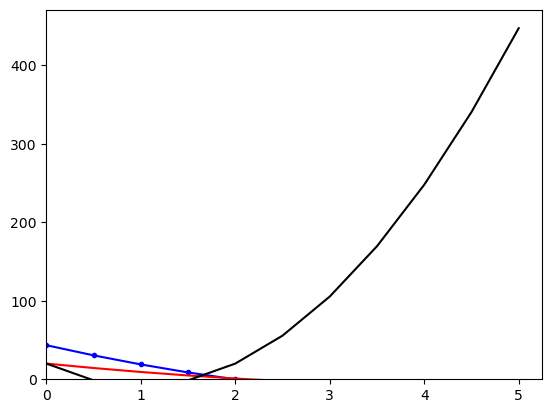

In [174]:
v0 = 20 #m/s
L = 1 #m
t0 = 5 #s
dt = 0.5 #s
N = int(t0/dt) + 1 #diskretizacija
print('diskretizacija: ', N)
kapa = 1
alpha = 0.001
toleranca = 10**(-5)

x0 = np.array([v0 for _ in range(N)])
sol = minimize(cenovna, x0=x0, args=(dt, L, kapa, alpha, v0), constraints=({'type': 'eq', 'fun': lambda x: sum(x)-x[-1]/2+v0/2-N}))
#sol = minimize(cenovna, x0=x0, args=(dt, L, kapa, alpha, v0))

hitrost = sol.x
print(sol.fun)
t = np.linspace(0, t0, N)
v1 = ekstremna_v(t,v0,t0,L)
v2 = v(t,v0)
plt.plot(t, hitrost*3.6, 'b.-')
plt.plot(t, v1, 'r')
plt.plot(t, v2, 'k')
plt.xlim(xmin=0.0)
plt.ylim(ymin=0.0)
plt.show()

0.21910376721503136

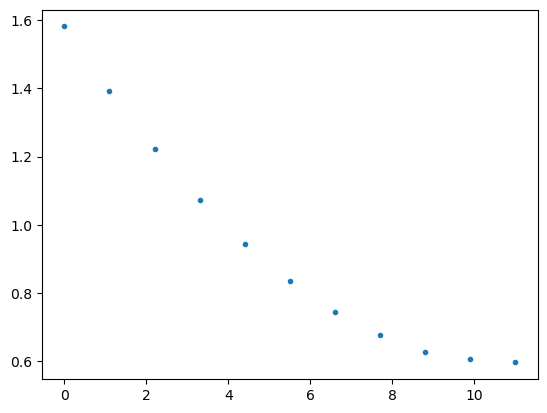

In [172]:
def funkcija(tocke_hitrost,zacet_speed):

    n=len(tocke_hitrost)
    dt=1/(n-1)
    vsota1=0

    #zacetno
    vsota1+=0.5*((tocke_hitrost[0]-zacet_speed))**2

    for i in range(n-1):
        vsota1+=((tocke_hitrost[i+1]-tocke_hitrost[i]))**2
    vsota1+=0.5*((tocke_hitrost[i]-tocke_hitrost[i-1]))**2
    return vsota1
def cenovna(x, dt, L, kapa, alpha, v0):
    ''''x - hitrost'''
    n = len(x)
    F = 0.5 * ((x[0]- v0))**2 + 0.5 * ((x[-1]-x[-2]))**2
    exp = 0.5 * x[0] + 0.5 * x[-1]
    for i in range(1, n):
        F += ((x[i]-x[i-1]))**2
        exp += x[i]
    #F =+ np.exp(kapa*(exp - (1+alpha)*L/dt)) + np.exp(kapa*((1-alpha)*L/dt - exp))
    return F
zacetna_hitrost = 2
hitrost=np.ones(N)*zacetna_hitrost
opt=minimize(funkcija,hitrost,args=zacetna_hitrost,constraints=({'type': 'eq', 'fun': lambda x: sum(x)-x[-1]/2+zacetna_hitrost/2-N}))
x=np.linspace(0,N,N)
plt.plot(x,opt.x,'.')
opt.fun

In [126]:
funkcija(x, v0), cenovna(x, dt,L,kapa,alpha,v0)

(57.3234722222222, 57.32347222222221)